# Decision Tree V3

For V3, I wanted to see if changing the minimum number of samples needed to keep splitting would improve the Decision Tree. I kept the best depths from V2 and used the same training and validation samples.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.decision_tree import DecisionTreeClassifier

min_samples_values = [1, 5, 10, 20, 40]
result_dir = project_root / "results" / "decision_tree"
v2_summary = pd.read_csv(result_dir / "decision_tree_v2_summary.csv")


I started by testing the different min_samples values on the image dataset.

In [2]:
X, y, _, _ = load_task("image")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
image_X_train = X_train[:200]
image_y_train = y_train[:200]
image_X_val = X_val[:200]
image_y_val = y_val[:200]
assert image_X_train.shape == (200, 500)
assert image_X_val.shape == (200, 500)
v2_validation = pd.read_csv(result_dir / "decision_tree_v2_image_validation.csv")
v2_result = v2_summary.loc[(v2_summary["dataset"] == "image") & (v2_summary["max_depth"] == 2)].iloc[0]
assert v2_validation["validation_index"].tolist() == list(range(200))
assert v2_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_models = {}
image_validation_predictions = {}
for min_samples in min_samples_values:
    clf = DecisionTreeClassifier(max_depth=2, min_samples=min_samples)
    print(f"Fitting image: depth=2, min_samples={min_samples}, 200 training samples, 500 features")
    start = perf_counter()
    clf.fit(image_X_train, image_y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(image_X_train, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_models[min_samples] = clf
    image_validation_predictions[min_samples] = y_pred
    if min_samples == 1:
        assert training_accuracy == v2_result["training_accuracy"] == 0.095
        assert validation_accuracy == v2_result["validation_accuracy"] == 0.045
        assert y_pred == v2_validation["predicted_label"].tolist()
        print("min_samples=1 reproduces selected V2 accuracies and all validation predictions exactly.")
    image_rows.append({
        "dataset": "image",
        "version": "V3",
        "criterion": "entropy",
        "max_depth": clf.max_depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(image_X_train),
        "validation_samples": len(image_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"min_samples={min_samples}, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
image_summary = pd.DataFrame(image_rows)


Fitting image: depth=2, min_samples=1, 200 training samples, 500 features
min_samples=1 reproduces selected V2 accuracies and all validation predictions exactly.
min_samples=1, training=9.50%, validation=4.50%
Fit time=1.938633 s, validation prediction time=0.000400 s
Fitting image: depth=2, min_samples=5, 200 training samples, 500 features
min_samples=5, training=9.50%, validation=4.50%
Fit time=1.870140 s, validation prediction time=0.000392 s
Fitting image: depth=2, min_samples=10, 200 training samples, 500 features
min_samples=10, training=9.50%, validation=4.50%
Fit time=1.994853 s, validation prediction time=0.001577 s
Fitting image: depth=2, min_samples=20, 200 training samples, 500 features
min_samples=20, training=9.50%, validation=4.50%
Fit time=3.091788 s, validation prediction time=0.000389 s
Fitting image: depth=2, min_samples=40, 200 training samples, 500 features
min_samples=40, training=9.50%, validation=4.50%
Fit time=1.876851 s, validation prediction time=0.000534 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
X, y, _, _ = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
sentiment_X_train = X_train[:200]
sentiment_y_train = y_train[:200]
sentiment_X_val = X_val[:200]
sentiment_y_val = y_val[:200]
assert sentiment_X_train.shape == (200, 768)
assert sentiment_X_val.shape == (200, 768)
v2_validation = pd.read_csv(result_dir / "decision_tree_v2_sentiment_validation.csv")
v2_result = v2_summary.loc[(v2_summary["dataset"] == "sentiment") & (v2_summary["max_depth"] == 3)].iloc[0]
assert v2_validation["validation_index"].tolist() == list(range(200))
assert v2_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_models = {}
sentiment_validation_predictions = {}
for min_samples in min_samples_values:
    clf = DecisionTreeClassifier(max_depth=3, min_samples=min_samples)
    print(f"Fitting sentiment: depth=3, min_samples={min_samples}, 200 training samples, 768 features")
    start = perf_counter()
    clf.fit(sentiment_X_train, sentiment_y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_models[min_samples] = clf
    sentiment_validation_predictions[min_samples] = y_pred
    if min_samples == 1:
        assert training_accuracy == v2_result["training_accuracy"] == 0.675
        assert validation_accuracy == v2_result["validation_accuracy"] == 0.45
        assert y_pred == v2_validation["predicted_label"].tolist()
        print("min_samples=1 reproduces selected V2 accuracies and all validation predictions exactly.")
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V3",
        "criterion": "entropy",
        "max_depth": clf.max_depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(sentiment_X_train),
        "validation_samples": len(sentiment_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"min_samples={min_samples}, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
sentiment_summary = pd.DataFrame(sentiment_rows)


Fitting sentiment: depth=3, min_samples=1, 200 training samples, 768 features
min_samples=1 reproduces selected V2 accuracies and all validation predictions exactly.
min_samples=1, training=67.50%, validation=45.00%
Fit time=20.001645 s, validation prediction time=0.001924 s
Fitting sentiment: depth=3, min_samples=5, 200 training samples, 768 features
min_samples=5, training=67.50%, validation=45.00%
Fit time=18.388440 s, validation prediction time=0.000559 s
Fitting sentiment: depth=3, min_samples=10, 200 training samples, 768 features
min_samples=10, training=67.50%, validation=45.00%
Fit time=19.988653 s, validation prediction time=0.001329 s
Fitting sentiment: depth=3, min_samples=20, 200 training samples, 768 features
min_samples=20, training=67.50%, validation=45.00%
Fit time=37.249875 s, validation prediction time=0.003536 s
Fitting sentiment: depth=3, min_samples=40, 200 training samples, 768 features
min_samples=40, training=64.00%, validation=39.00%
Fit time=23.583127 s, vali

I plotted the training and validation accuracies to compare the different settings.

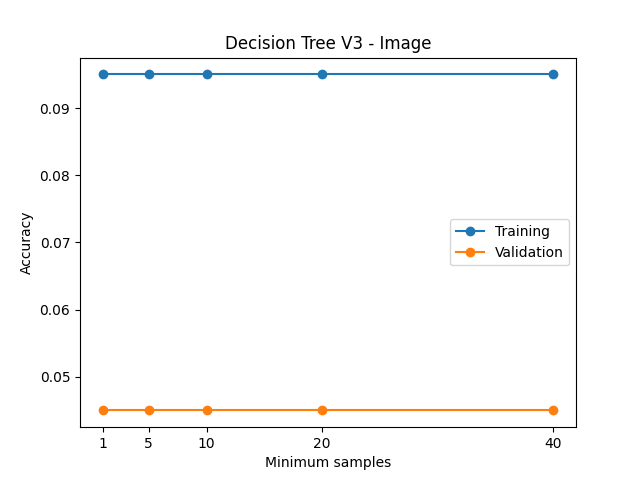

In [4]:
plt.figure()
plt.plot(min_samples_values, image_summary["training_accuracy"], marker="o", label="Training")
plt.plot(min_samples_values, image_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Minimum samples")
plt.ylabel("Accuracy")
plt.title("Decision Tree V3 - Image")
plt.xticks(min_samples_values)
plt.legend()
plt.savefig(result_dir / "decision_tree_v3_image_min_samples.png")
plt.show()


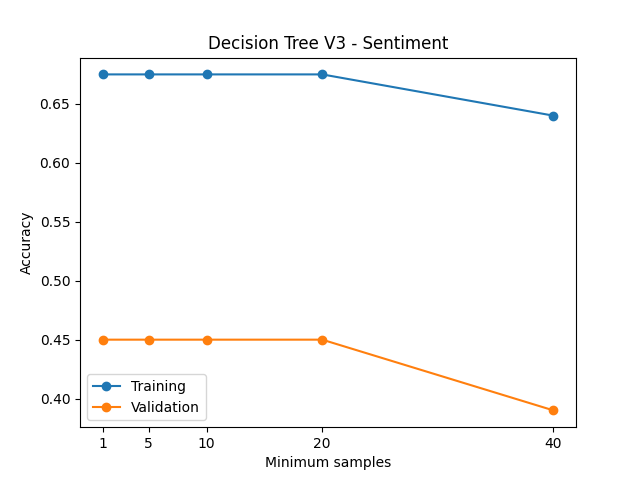

In [5]:
plt.figure()
plt.plot(min_samples_values, sentiment_summary["training_accuracy"], marker="o", label="Training")
plt.plot(min_samples_values, sentiment_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Minimum samples")
plt.ylabel("Accuracy")
plt.title("Decision Tree V3 - Sentiment")
plt.xticks(min_samples_values)
plt.legend()
plt.savefig(result_dir / "decision_tree_v3_sentiment_min_samples.png")
plt.show()


Finally, I compared the validation results to choose the best min_samples value for each dataset.

In [6]:
image_best_accuracy = -1
for row in image_rows:
    # Values are ascending, so the smaller min_samples wins an accuracy tie.
    if row["validation_accuracy"] > image_best_accuracy:
        image_best_min_samples = row["min_samples"]
        image_best_accuracy = row["validation_accuracy"]
print(f"Image: selected min_samples={image_best_min_samples}, validation accuracy={image_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_min_samples],
}).to_csv(result_dir / "decision_tree_v3_image_validation.csv", index=False)

sentiment_best_accuracy = -1
for row in sentiment_rows:
    # Values are ascending, so the smaller min_samples wins an accuracy tie.
    if row["validation_accuracy"] > sentiment_best_accuracy:
        sentiment_best_min_samples = row["min_samples"]
        sentiment_best_accuracy = row["validation_accuracy"]
print(f"Sentiment: selected min_samples={sentiment_best_min_samples}, validation accuracy={sentiment_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_min_samples],
}).to_csv(result_dir / "decision_tree_v3_sentiment_validation.csv", index=False)

summary = pd.DataFrame(image_rows + sentiment_rows)
assert len(summary) == 10
summary.to_csv(result_dir / "decision_tree_v3_summary.csv", index=False)
print(summary.to_string(index=False))

image_same_predictions = all(
    predictions == image_validation_predictions[1]
    for predictions in image_validation_predictions.values()
)
print(f"Image: all settings give the same validation predictions: {image_same_predictions}")

sentiment_same_predictions = all(
    predictions == sentiment_validation_predictions[1]
    for predictions in sentiment_validation_predictions.values()
)
print(f"Sentiment: all settings give the same validation predictions: {sentiment_same_predictions}")


Image: selected min_samples=1, validation accuracy=4.50%
Sentiment: selected min_samples=1, validation accuracy=45.00%
  dataset version criterion  max_depth  min_samples  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  fit_time_seconds  prediction_time_seconds
    image      V3   entropy          2            1       False               200                 200              0.095                0.045          1.938633                 0.000400
    image      V3   entropy          2            5       False               200                 200              0.095                0.045          1.870140                 0.000392
    image      V3   entropy          2           10       False               200                 200              0.095                0.045          1.994853                 0.001577
    image      V3   entropy          2           20       False               200                 200              0.095                0.045

In [7]:
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v3_row = {
    "version": "V3",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": "",
    "notes": f"Tested min_samples=1, 5, 10, 20, 40; image max_depth=2, sentiment max_depth=3; selected image min_samples={image_best_min_samples}, sentiment min_samples={sentiment_best_min_samples}; 200 training samples per dataset, entropy.",
}
matching = tracker["version"] == "V3"
if matching.any():
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, column] = v3_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v3_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle submission_filename                                                                                                                                                                            notes
     V1                     0.045                          0.45                                   False                                                                                                             max_depth=3, min_samples=1; 200 training examples per dataset; entropy/information gain.
     V2                     0.045                          0.45                                   False                                                                    Tested max_depth=2, 3, 5, 8; selected image depth=2, sentiment depth=3; min_samples=1, 200 training samples per dataset, entropy.
     V3                     0.045                          0.45                                  

I kept min_samples=1 for both datasets after the ties, since none of the larger values improved validation accuracy. Image predictions stayed the same for all five settings, while sentiment validation accuracy dropped from 45% to 39% at min_samples=40.